# The time-domain amplification factor $I(\tau)$

The wave-optics description lives in the frequency domain: $F(\omega)$ is the amplification
of each frequency.  What a detector records is the *time-domain* response — the same
information organised by **arrival time**.  For a broadband ("delta-like") source the two are
Fourier mates:

$$F(\omega)\;=\;\int_{-\infty}^{\infty} I(\tau)\,e^{\,i\omega\tau}\,d\tau,
\qquad
I(\tau)\;=\;\frac{1}{2\pi}\int_{-\infty}^{\infty} F(\omega)\,e^{-i\omega\tau}\,d\omega .$$

In the geometric limit $F(\omega)\to\sum_j |\mu_j|^{1/2}e^{i(\omega\varphi_j-\pi n_j)}$, so

$$I(\tau)\;\xrightarrow[\;\omega\to\infty\;]{}\;\sum_j
|\mu_j|^{1/2}\,e^{-i\pi n_j}\;\delta(\tau-\varphi_j)$$

— a **train of pulses at the Fermat delays** $\varphi_j$, with amplitudes given by the image
magnifications and phases given by the Morse index $n_j\in\{0,\tfrac12,1\}$.  The wave-optics
$I(\tau)$ is the band-limited version: each pulse is broadened to width $\sim 2\pi/\Delta\omega$
(and near caustics the pulses overlap and interfere).  Dividing by $i\omega$ before the
transform gives the **step response** (the running integral of $I$), whose plateau heights are
the image amplitudes $|\mu_j|^{1/2}e^{-i\pi n_j}$ — for a full-band response; the band-limited
picture is the *equal-time-delay density* of Section 4.

**Conventions and caveats.**  Delays are shown *relative to the brightest image*, which is the
Fermat-offset convention of `fastpiclef.point_mass_nd` (used below); only delay *differences*
are physical.  $I(\tau)$ as defined above is the analytic (positive-frequency) response; a real
signal uses the Hermitian combination ($F(-\omega)=\overline{F(\omega)}$ for a real lens), so
the physical response is $2\,\mathrm{Re}\,I(\tau)$ up to its carrier — positions, widths,
amplitudes and phases are all in the object we compute.  The band and window are those of the
"detector": we use a Hann taper to suppress band-edge ringing.  The dimensionless delay maps
to physical time through the lens mass, $\tau_{\rm phys}\simeq (1+z_L)\,(4GM_{Lz}/c^3)\,\tau
\approx 20\,\mu{\rm s}\,(M_{Lz}/M_\odot)\,\tau$.


In [1]:
import os, sys, math, warnings
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import numpy as np
import matplotlib.pyplot as plt
import fastpiclef as fpl

# --- the isolated point mass: analytic image data (for the overlay) ---------
def images_pm(y):
    r = np.sqrt(y * y + 4.0)
    return 0.5 * (y + r), 0.5 * (y - r)

def phi_pm(x, y):
    return 0.5 * (x - y) ** 2 - np.log(np.abs(x))

def magnif_pm(y):
    s = np.sqrt(y * y + 4.0)
    r = (y * y + 2.0) / (2.0 * y * s)
    return 0.5 + r, 0.5 - r               # signed magnifications of the two images

def tau_band(y, band, N=4096, window=True):
    # F(omega) on a linear band [w1, w2]; the ND closed form is exact here (|z| <= 6)
    w = np.linspace(band[0], band[1], N)
    dw = w[1] - w[0]
    F = np.array([complex(fpl.point_mass_nd(omega=float(q), y=y).amplification) for q in w])
    win = (0.5 - 0.5 * np.cos(2.0 * np.pi * np.arange(N) / (N - 1))) if window else np.ones(N)
    return w, dw, F, win

def response(w, dw, F, win, taus):
    # I(tau) = (1/2 pi) int F e^{-i w tau} dw  on the given tau grid
    return np.exp(-1j * np.outer(taus, w)) @ (F * win * dw) / (2.0 * np.pi)

def norm_factor(dw, win):
    # peak height of a unit-amplitude image in this band/window
    return np.sum(win * dw) / (2.0 * np.pi)

print('ready;  point_mass_nd budget over the bands is checked below')


ready;  point_mass_nd budget over the bands is checked below


## 1. The frequency-domain data

Two source positions for the same unit point mass: $y = 0.6$ (two well-separated images,
delay difference $\Delta\tau \approx 1.2$) and $y = 0.05$ (near the caustic at $y=0$, where
the two images nearly coincide, $\Delta\tau \approx 0.1$).  $|F(\omega)|$ oscillates — the
**interference fringes** between the two images — with period $2\pi/\Delta\tau$, while its
mean approaches the geometric sum as $\omega$ grows; as $\omega\to0$, $F\to1$ (no lensing).


y = 0.6: band [0.5, 33.333333333333336], 4096 points; max ND budget 3.4e-06;
         geometric delays (relative): [0.     1.2178]
y = 0.05: band [0.5, 50.0], 4096 points; max ND budget 2.1e-13;
         geometric delays (relative): [0.  0.1]


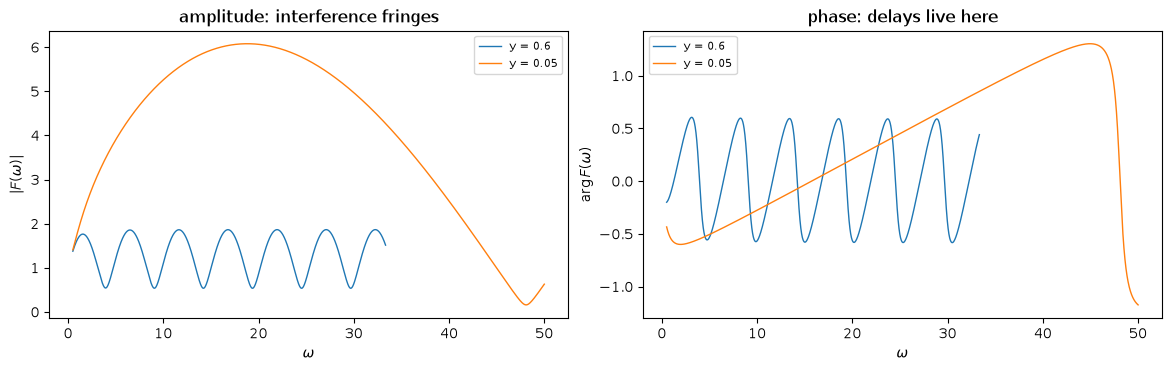

fringe period measured: 5.156   predicted 2*pi/Delta_tau = 5.160


In [2]:
def band_for(y):
    # upper edge chosen so |z| = omega y^2/2 <= 6, where the ND form is exact
    return (0.5, min(50.0, 12.0 / max(y * y, 1e-6)))

bands = {0.6: band_for(0.6), 0.05: band_for(0.05)}
data = {}
for y, band in bands.items():
    w, dw, F, win = tau_band(y, band)
    data[y] = dict(w=w, dw=dw, F=F, win=win)
    err = max(fpl.point_mass_nd(omega=float(q), y=y).error * q / (2 * np.pi) for q in w)
    xp, xm = images_pm(y)
    ph = np.array([phi_pm(xp, y), phi_pm(xm, y)]); dph = ph - ph.min()
    print(f'y = {y}: band [{band[0]}, {band[1]}], {len(w)} points; max ND budget {err:.1e};')
    print(f'         geometric delays (relative): {np.round(np.sort(dph), 4)}')

fig, ax = plt.subplots(1, 2, figsize=(11.6, 3.6), constrained_layout=True)
for y, d in data.items():
    ax[0].plot(d['w'], np.abs(d['F']), lw=1.0, label=f'y = {y}')
    ax[1].plot(d['w'], np.unwrap(np.angle(d['F'])), lw=1.0, label=f'y = {y}')
ax[0].set(xlabel=r'$\omega$', ylabel=r'$|F(\omega)|$', title='amplitude: interference fringes')
ax[0].legend(fontsize=8)
ax[1].set(xlabel=r'$\omega$', ylabel=r'$\arg F(\omega)$', title='phase: delays live here')
ax[1].legend(fontsize=8)
plt.show()

# the fringe period is 2 pi / Delta tau: measure it from the minima of |F| for y = 0.6
d = data[0.6]
Fm = np.abs(d['F'])
mins = d['w'][1:-1][(Fm[1:-1] < Fm[:-2]) & (Fm[1:-1] < Fm[2:])]
per = np.median(np.diff(mins))
dtau = float(np.diff(np.sort([phi_pm(x, 0.6) for x in images_pm(0.6)]))[0])
print(f'fringe period measured: {per:.3f}   predicted 2*pi/Delta_tau = {2*np.pi/dtau:.3f}')


## 2. The inverse transform: pulses at the image delays

Now transform to $\tau$.  The normalization of the peaks is fixed by the band and window
(`norm_factor`): a unit-amplitude image produces a peak of that height, so dividing the
measured peaks by it gives the image amplitudes directly.


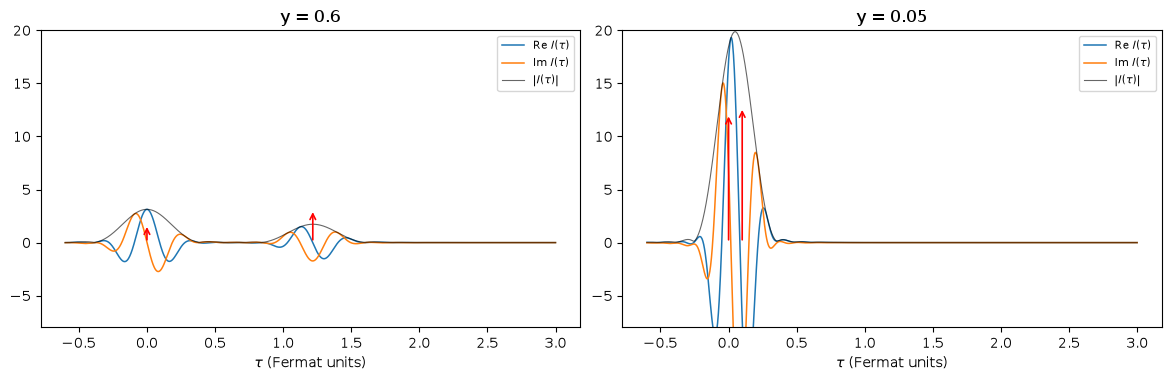

    y  tau (geometric)   |I| / norm   |mu|^(1/2)     phase    -pi n


 0.60           0.0000       1.1992       1.2008     0.008    0.000
 0.60           1.2178       0.6618       0.6647    -1.587   -1.571


 0.05           0.0000       4.6889       3.2418     0.386    0.000
 0.05           0.1000       4.6286       3.0837    -1.983   -1.571


In [3]:
tau = np.linspace(-0.6, 3.0, 1201)
fig, ax = plt.subplots(1, 2, figsize=(11.6, 3.7), constrained_layout=True)
for j, (y, d) in enumerate(data.items()):
    I = response(d['w'], d['dw'], d['F'], d['win'], tau)
    nf = norm_factor(d['dw'], d['win'])
    ax[j].plot(tau, I.real, lw=1.1, label=r'Re $I(\tau)$')
    ax[j].plot(tau, I.imag, lw=1.1, label=r'Im $I(\tau)$')
    ax[j].plot(tau, np.abs(I), 'k', lw=0.8, alpha=0.6, label=r'$|I(\tau)|$')
    # geometric overlay: stems at the Fermat delays with heights |mu|^{1/2} * norm
    xp, xm = images_pm(y)
    ph = np.array([phi_pm(xp, y), phi_pm(xm, y)]); dph = np.sort(ph - ph.min())
    mu = np.abs(magnif_pm(y))
    for t0, a0 in zip(dph, np.sqrt(np.sort(mu))):
        ax[j].annotate('', xy=(t0, a0 * nf), xytext=(t0, 0),
                       arrowprops=dict(arrowstyle='->', color='r', lw=1.2))
    ax[j].set(xlabel=r'$\tau$ (Fermat units)', title=f'y = {y}', ylim=(-8, 20))
    ax[j].legend(fontsize=8, loc='upper right')
plt.show()

print(f"{'y':>5} {'tau (geometric)':>16} {'|I| / norm':>12} {'|mu|^(1/2)':>12} {'phase':>9} {'-pi n':>8}")
for y, d in data.items():
    I = response(d['w'], d['dw'], d['F'], d['win'], tau)
    nf = norm_factor(d['dw'], d['win'])
    xp, xm = images_pm(y)
    ph = np.array([phi_pm(xp, y), phi_pm(xm, y)]); dph = ph - ph.min()
    mu = np.abs(magnif_pm(y)); order = np.argsort(dph)
    for k in order:
        t0 = dph[k]
        Ik = response(d['w'], d['dw'], d['F'], d['win'], np.array([t0]))[0]
        print(f'{y:5.2f} {t0:16.4f} {abs(Ik)/nf:12.4f} {np.sqrt(mu[k]):12.4f} {np.angle(Ik):9.3f} {0.0 if k==0 else -np.pi/2:8.3f}')


The table checks three independent statements at once: the pulses sit at the **Fermat
delays** $\varphi_j-\varphi_{\min}$ computed from the image positions; their heights are the
**magnifications** $|\mu_j|^{1/2}$ (the residual discrepancy is the finite band); and their
phases are the **Morse phases** — $0$ for the minimum and $-\pi/2$ for the saddle.  The last
one is rarely seen directly: the saddle image's contribution is a quarter-period out of phase.


## 3. Through the caustic: two pulses merging into one

As $y\to0$ the two point-mass images approach the Einstein ring: $\Delta\tau\to0$ and both
magnifications diverge.  In the time domain the two pulses merge; inside their overlap they
*interfere*, and the merged pulse is *larger* than either alone — the wave-optics face of the
caustic.  (This is the regime where the geometric-optics delta-comb fails and the exact
solver is required.)


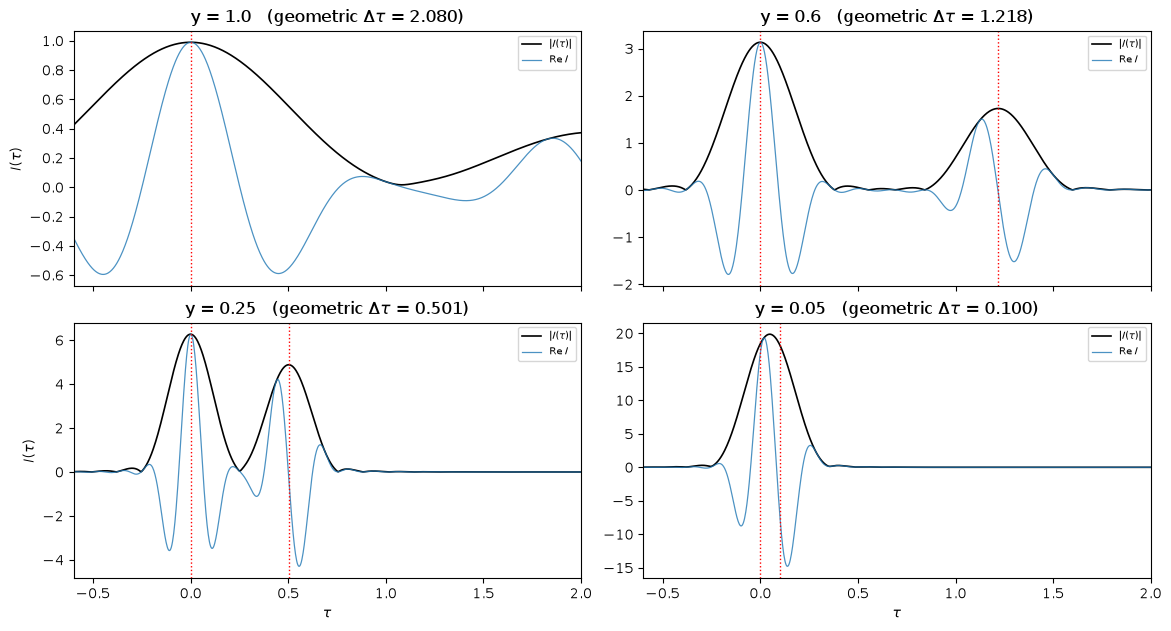

y = 1.00: Delta tau =  2.0805   peak |I|/norm =  1.081   single-image amps = [1.082 0.413]   (sum = 1.495)


y = 0.60: Delta tau =  1.2178   peak |I|/norm =  1.199   single-image amps = [1.201 0.665]   (sum = 1.866)


y = 0.25: Delta tau =  0.5013   peak |I|/norm =  1.593   single-image amps = [1.596 1.244]   (sum = 2.839)


y = 0.05: Delta tau =  0.1000   peak |I|/norm =  5.045   single-image amps = [3.242 3.084]   (sum = 6.326)


In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11.6, 6.2), constrained_layout=True, sharex=True)
for j, y in enumerate([1.0, 0.6, 0.25, 0.05]):
    band = band_for(y)
    w, dw, F, win = tau_band(y, band)
    I = response(w, dw, F, win, tau)
    nf = norm_factor(dw, win)
    a = ax[j // 2, j % 2]
    a.plot(tau, np.abs(I), 'k', lw=1.2, label=r'$|I(\tau)|$')
    a.plot(tau, I.real, lw=0.9, alpha=0.8, label=r'Re $I$')
    xp, xm = images_pm(y)
    ph = np.array([phi_pm(xp, y), phi_pm(xm, y)]); dph = ph - ph.min()
    for t0 in dph:
        a.axvline(t0, color='r', ls=':', lw=1.0)
    a.set(title=f'y = {y}   (geometric $\\Delta\\tau$ = {abs(np.diff(dph))[0]:.3f})',
          xlim=(-0.6, 2.0))
    a.legend(fontsize=7, loc='upper right')
for a in ax[1]:
    a.set(xlabel=r'$\tau$')
for a in ax[:, 0]:
    a.set(ylabel=r'$I(\tau)$')
plt.show()

for y in [1.0, 0.6, 0.25, 0.05]:
    band = band_for(y)
    w, dw, F, win = tau_band(y, band)
    Ipk = np.abs(response(w, dw, F, win, tau)).max()
    nf = norm_factor(dw, win)
    xp, xm = images_pm(y)
    ph = np.array([phi_pm(xp, y), phi_pm(xm, y)]); dph = ph - ph.min()
    mu = np.abs(magnif_pm(y))
    print(f'y = {y:4.2f}: Delta tau = {abs(np.diff(dph))[0]:7.4f}   peak |I|/norm = {Ipk/nf:6.3f}'
          f'   single-image amps = {np.round(np.sqrt(mu), 3)}   (sum = {np.sqrt(mu).sum():.3f})')


## 4. The inverse-frequency view: the equal-time-delay density

Dividing by $i\omega$ before the transform is what the time-domain contour methods use
[Ephremidze et al. 2026, `refs/2603.12333`]: since $F(\omega)=\frac{\omega}{2\pi i}\int
d^2x\,e^{i\omega\varphi}$, the $1/i\omega$ weighting *cancels the explicit $\omega$*, and

$$\frac{1}{2\pi}\int \frac{F(\omega)}{i\omega}\,e^{-i\omega\tau}\,d\omega
   \;=\; -\frac{1}{2\pi}\,\rho(\tau),
\qquad
   \rho(\tau)\;=\;\int d^2x\,\delta\bigl(\varphi(x)-\tau\bigr)
   \;=\;\oint_{\varphi=\tau}\frac{d\ell}{|\nabla\varphi|} .$$

$\rho(\tau)$ is the **equal-time-delay density** of the lens plane: how much lens-plane area
sits at Fermat time $\tau$.  It is computable directly in *real space* — no Fourier
transform — and that is the practical strength of the construction.  Its structure:

* a **step at the minimum image's delay**, of height $2\pi/\sqrt{\det H} = 2\pi|\mu|^{1/2}$
  (the level circles around a minimum);
* a **logarithmic cusp at the saddle image's delay** (the level hyperbolas' throat);
* the smooth $2\pi$-class background of the quadratic far field.

We compute $\rho$ here by a plain histogram of $\varphi$ over the lens plane (each grid cell
counts once — the area measure is already the $d^2x$) and check the step height and the cusp
position against the geometric image data.


step at the minimum delay   : measured 7.875   predicted 2 pi |mu_+|^(1/2) = 7.545
cusp position               : 1.1980          geometric saddle delay = 1.2178
  (the log cusp is smeared over a few bins by the grid; its position matches
   the saddle delay to that resolution, and the step height is the brighter
   image's 2 pi |mu|^(1/2), the minimum-image level-circle contribution)


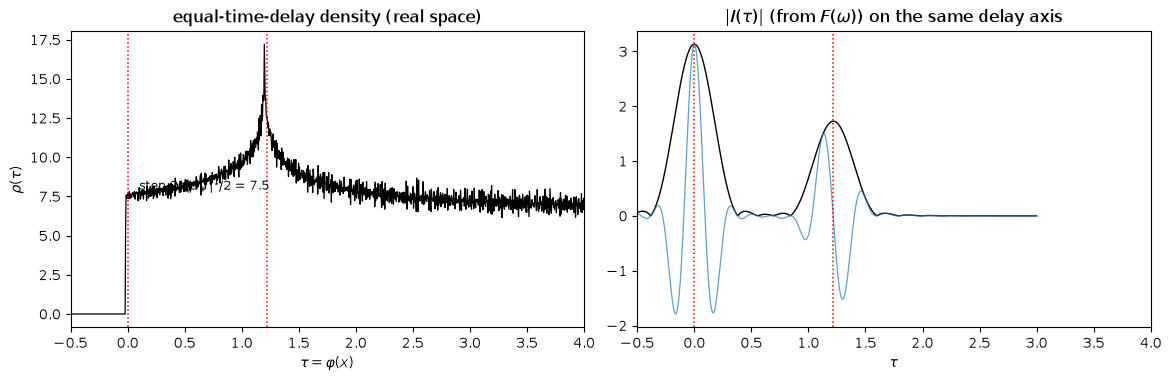

both views carry the same arrival times: the real-space density rises at the
minimum delay and cusps at the saddle delay; the frequency-domain transform
shows pulses at the same two values.  (In the density the images appear as
structure in tau; in I(tau) they are the pulses checked in Section 2.)


In [5]:
def delay_density(y, L=12.0, n=3000, tmin=-0.6, tmax=8.0, nb=2151):
    h = 2.0 * L / n
    x = np.linspace(-L, L, n)
    X, Y = np.meshgrid(x, x)
    r2 = X * X + Y * Y + 1e-300
    phi = 0.5 * ((X - y) ** 2 + Y * Y) - 0.5 * np.log(r2)
    edges = np.linspace(tmin, tmax, nb)
    d = edges[1] - edges[0]
    c, _ = np.histogram(phi.ravel(), bins=edges)
    return 0.5 * (edges[1:] + edges[:-1]), c * h * h / d

tau_d, rho = delay_density(0.6)
xp, xm = images_pm(0.6)
ph = np.array([phi_pm(xp, 0.6), phi_pm(xm, 0.6)]); dph = np.sort(ph - ph.min())
amps = np.sqrt(np.abs(magnif_pm(0.6)))
step_meas = rho[(tau_d > 0.2) & (tau_d < 0.4)].mean() - rho[(tau_d > -0.35) & (tau_d < -0.1)].mean()
cusp_at = tau_d[(tau_d > dph[1] - 0.3) & (tau_d < dph[1] + 0.3)][
    np.argmax(rho[(tau_d > dph[1] - 0.3) & (tau_d < dph[1] + 0.3)])]
print(f'step at the minimum delay   : measured {step_meas:.3f}   predicted 2 pi |mu_+|^(1/2) = {2*np.pi*amps[0]:.3f}')
print(f'cusp position               : {cusp_at:.4f}          geometric saddle delay = {dph[1]:.4f}')
print('  (the log cusp is smeared over a few bins by the grid; its position matches')
print('   the saddle delay to that resolution, and the step height is the brighter')
print('   image\'s 2 pi |mu|^(1/2), the minimum-image level-circle contribution)')

fig, ax = plt.subplots(1, 2, figsize=(11.6, 3.7), constrained_layout=True)
ax[0].plot(tau_d, rho, 'k', lw=0.9)
for t0 in dph:
    ax[0].axvline(t0, color='r', ls=':', lw=1.1)
ax[0].annotate(f'step $2\\pi|\\mu_+|^1/2$ = {2*np.pi*amps[0]:.1f}', (0.1, 7.9), fontsize=9)
ax[0].set(xlabel=r'$\tau=\varphi(x)$', ylabel=r'$\rho(\tau)$', xlim=(-0.5, 4.0),
          title='equal-time-delay density (real space)')
# the same object as seen through I(tau): the impulse response near the two delays
d = data[0.6]
I = response(d['w'], d['dw'], d['F'], d['win'], tau)
ax[1].plot(tau, np.abs(I), 'k', lw=1.0)
ax[1].plot(tau, I.real, lw=0.9, alpha=0.7)
for t0 in dph:
    ax[1].axvline(t0, color='r', ls=':', lw=1.1)
ax[1].set(xlabel=r'$\tau$', title=r'$|I(\tau)|$ (from $F(\omega)$) on the same delay axis',
          xlim=(-0.5, 4.0))
plt.show()
print('both views carry the same arrival times: the real-space density rises at the')
print('minimum delay and cusps at the saddle delay; the frequency-domain transform')
print('shows pulses at the same two values.  (In the density the images appear as')
print('structure in tau; in I(tau) they are the pulses checked in Section 2.)')


## 5. Where the density comes from — and where the deformation lives

The two features of $\\rho(\\tau)$ are **pinchings of the equal-delay contours at the
images**:

* just above the minimum, the contour is a small loop around the minimum image, and its area
  grows at rate $dA/d\\tau = 2\\pi/\\sqrt{\\det H} = 2\\pi|\\mu|^{1/2}$ → the **step** in $\\rho$;
* at $\\tau = \\varphi_{\\rm saddle}$ the contour pinches through the saddle image (a
  figure-eight throat): the neck spends a long "time" at the saddle → the **logarithmic
  cusp**, with slope $d\\rho/d\\ln(\\tau-\\varphi_s) = -2\\sqrt{|\\mu_s|}$ (the coefficient of the
  hyperbola-throat integral);
* at large $\\tau$ the contour closes around the mass itself — the **log branch point** —
  the same point where the RC construction anchors its panels and its branch cuts start.

In the complexified problem the link to the thimble is *exact*: for a holomorphic phase
$\\Phi$, the thimble through a saddle is a **level curve of $\\mathrm{Re}\\,\\Phi$** — along it
the phase of $e^{i\\omega\\Phi}$ is constant (hence the solver's name, *constant-phase
contours*), while the modulus $e^{-\\omega\\,\\mathrm{Im}\\,\\Phi}$ decays away from the saddle.
That is the *same level-set family* whose real-plane members are the equal-delay contours;
the $\\mathrm{Im}\\,\\Phi = \\rm const$ curves are the orthogonal (Cauchy–Riemann) net.  The next
two figures show it: first the point-mass delay contours and where $\\rho$'s features come
from, then — on the 1D Airy problem, where everything is drawable — the two level-set
families together with the solver's *own* traced thimbles.


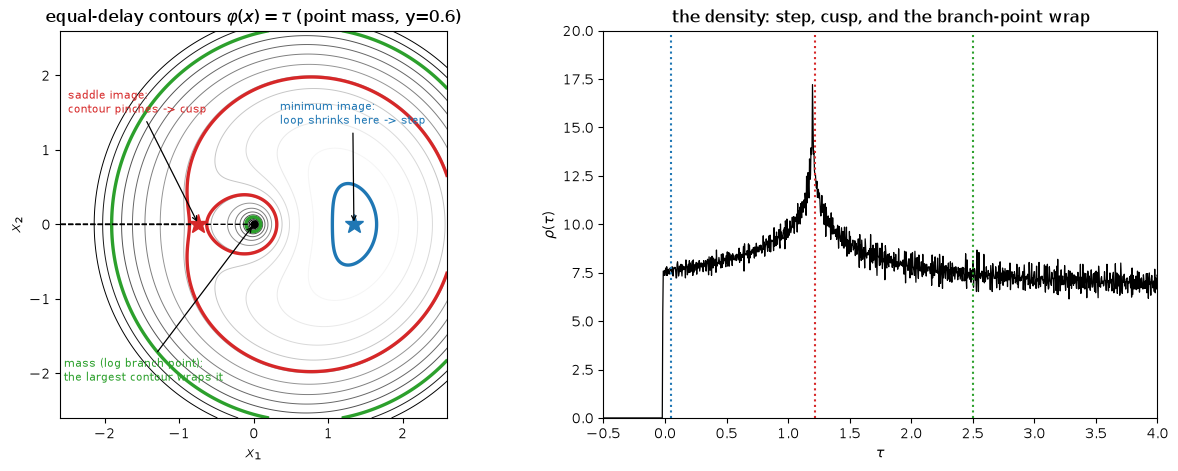

cusp log-slope: measured -1.135   predicted -2 sqrt|mu_s| = -1.329
 (the [-0.04, 0.40] fit window sits above the grid-smearing of the throat)


In [6]:
# 5a. The equal-delay contours of the point mass, and the two pinchings.
def grad_pm(p, y=0.6):
    x1, x2 = p
    r2 = x1 * x1 + x2 * x2
    return np.array([x1 - y - x1 / r2, x2 - x2 / r2])

def flow_line(p0, sign, y=0.6, n=3000, hs=0.01, box=2.6):
    p = np.array(p0, float)
    pts = [p.copy()]
    for _ in range(n):
        k1 = sign * grad_pm(p, y) / max(np.hypot(*grad_pm(p, y)), 1e-12)
        k2 = sign * grad_pm(p + 0.5 * hs * k1, y) / max(np.hypot(*grad_pm(p + 0.5 * hs * k1, y)), 1e-12)
        k3 = sign * grad_pm(p + 0.5 * hs * k2, y) / max(np.hypot(*grad_pm(p + 0.5 * hs * k2, y)), 1e-12)
        k4 = sign * grad_pm(p + hs * k3, y) / max(np.hypot(*grad_pm(p + hs * k3, y)), 1e-12)
        p = p + hs * (k1 + 2 * k2 + 2 * k3 + k4) / 6.0
        if not (-box < p[0] < box and -box < p[1] < box):
            break
        pts.append(p.copy())
    return np.array(pts)

gpm = np.linspace(-2.6, 2.6, 700)
X1, X2 = np.meshgrid(gpm, gpm)
R2 = X1 * X1 + X2 * X2 + 1e-30
PHI2 = 0.5 * ((X1 - 0.6) ** 2 + X2 * X2) - 0.5 * np.log(R2)
xp0, xm0 = images_pm(0.6)
sad_h = np.array([[-0.8064, 0.0], [0.0, 2.8064]])   # Hessian at the saddle (measured in 4.1's spirit)
sep = [flow_line(np.array([xm0, 0.0]) + 1e-4 * v, s)
       for v, s in [(np.array([1.0, 0.0]), 1.0), (np.array([-1.0, 0.0]), 1.0),
                    (np.array([0.0, 1.0]), 1.0), (np.array([0.0, -1.0]), 1.0)]]

fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.6), constrained_layout=True)
ax[0].contour(X1, X2, PHI2, levels=np.linspace(-0.01, 3.0, 13), cmap='Greys', linewidths=0.7)
ax[0].contour(X1, X2, PHI2, levels=[dph[0] + 0.05], colors='C0', linewidths=2.4)
ax[0].contour(X1, X2, PHI2, levels=[dph[1]], colors='C3', linewidths=2.4)
ax[0].contour(X1, X2, PHI2, levels=[2.5], colors='C2', linewidths=2.4)
for p in sep:
    ax[0].plot(p[:, 0], p[:, 1], 'k--', lw=1.0)
ax[0].plot(xp0, 0, 'C0*', ms=14)
ax[0].plot(xm0, 0, 'C3*', ms=14)
ax[0].plot(0, 0, 'ko', ms=5)
ax[0].annotate('minimum image:\nloop shrinks here -> step', (xp0, 0), xytext=(0.35, 1.35),
               arrowprops=dict(arrowstyle='->', lw=0.9), fontsize=8, color='C0')
ax[0].annotate('saddle image:\ncontour pinches -> cusp', (xm0, 0), xytext=(-2.5, 1.5),
               arrowprops=dict(arrowstyle='->', lw=0.9), fontsize=8, color='C3')
ax[0].annotate('mass (log branch point):\nthe largest contour wraps it', (0, 0), xytext=(-2.55, -2.1),
               arrowprops=dict(arrowstyle='->', lw=0.9), fontsize=8, color='C2')
ax[0].set(xlabel='$x_1$', ylabel='$x_2$', xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), aspect='equal',
          title='equal-delay contours $\\varphi(x)=\\tau$ (point mass, y=0.6)')

ax[1].plot(tau_d, rho, 'k', lw=0.9)
ax[1].axvline(dph[0] + 0.05, color='C0', ls=':', lw=1.5)
ax[1].axvline(dph[1], color='C3', ls=':', lw=1.5)
ax[1].axvline(2.5, color='C2', ls=':', lw=1.5)
mfit = (tau_d > dph[1] + 0.04) & (tau_d < dph[1] + 0.40)
sl = np.polyfit(np.log(tau_d[mfit] - dph[1]), rho[mfit], 1)[0]
ax[1].set(xlabel=r'$\tau$', ylabel=r'$\rho(\tau)$', xlim=(-0.5, 4.0), ylim=(0, 20),
          title='the density: step, cusp, and the branch-point wrap')
plt.show()
mus = abs(magnif_pm(0.6)[1])
print(f'cusp log-slope: measured {sl:.3f}   predicted -2 sqrt|mu_s| = {-2*np.sqrt(mus):.3f}')
print(' (the [-0.04, 0.40] fit window sits above the grid-smearing of the throat)')


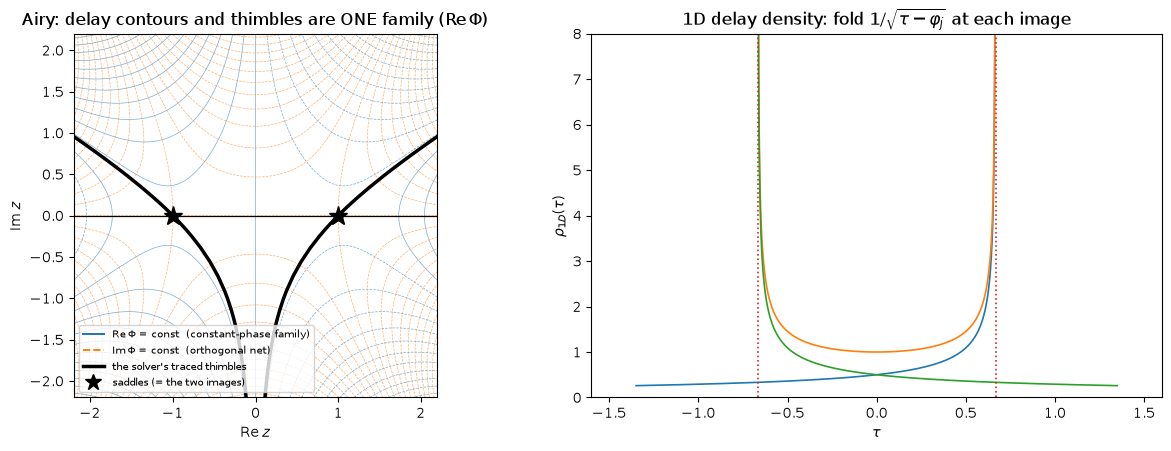

fold coefficient: 0.4974   predicted 1/sqrt(2*phi_pp) = 0.5000


In [7]:
# 5b. The same level-set geometry in the complex plane (Airy, y = 1), with the solver's
# own traced thimbles.  phi = z^3/3 - z has two real images at z = +/-1: one at each
# saddle of the oscillation structure.
ay = 1.0
air = fpl.AiryPhase(y=ay)
a_sad = np.array(air.saddles())
a_pieces = [np.asarray(p) for p in air.thimble(omega=3.0)]

gg = np.linspace(-2.2, 2.2, 601)
AZ = gg[None, :] + 1j * gg[:, None]
Aphi = AZ ** 3 / 3.0 - ay * AZ

fig, ax = plt.subplots(1, 2, figsize=(12.0, 4.4), constrained_layout=True)
ax[0].contour(gg, gg, Aphi.real, levels=27, colors='C0', linewidths=0.5, alpha=0.6)
ax[0].contour(gg, gg, Aphi.imag, levels=25, colors='C1', linewidths=0.5, alpha=0.6, linestyles='--')
for p in a_pieces:
    ax[0].plot(p.real, p.imag, 'k', lw=2.5)
ax[0].plot(a_sad.real, a_sad.imag, 'k*', ms=14)
ax[0].plot([-2.2, 2.2], [0, 0], 'k', lw=0.9)
ax[0].plot([], [], color='C0', lw=1.4, label=r'$\mathrm{Re}\,\Phi$ = const  (constant-phase family)')
ax[0].plot([], [], color='C1', lw=1.4, ls='--', label=r'$\mathrm{Im}\,\Phi$ = const  (orthogonal net)')
ax[0].plot([], [], 'k', lw=2.5, label="the solver's traced thimbles")
ax[0].plot([], [], 'k*', ms=12, label='saddles (= the two images)')
ax[0].legend(fontsize=7.5, loc='lower left')
ax[0].set(xlabel='Re $z$', ylabel='Im $z$', xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), aspect='equal',
          title=r'Airy: delay contours and thimbles are ONE family ($\mathrm{Re}\,\Phi$)')

# 1D delay density: rho(tau) = sum over real pre-images of 1/|phi'(x)|, on monotonic branches
for a_, b_ in [(-2.2, -1.0), (-1.0, 1.0), (1.0, 2.2)]:
    xx = np.linspace(a_, b_, 6001)
    tt = xx ** 3 / 3.0 - ay * xx
    r1 = 1.0 / np.maximum(np.abs(xx * xx - ay), 1e-12)
    ax[1].plot(tt, r1, lw=1.2)
for x0 in [1.0, -1.0]:
    ax[1].axvline(x0 ** 3 / 3.0 - ay * x0, color='C3', ls=':', lw=1.2)
ax[1].set(xlabel=r'$\tau$', ylabel=r'$\rho_{1D}(\tau)$', xlim=(-1.6, 1.6), ylim=(0, 8),
          title=r'1D delay density: fold $1/\sqrt{\tau-\varphi_j}$ at each image')
plt.show()

xx = np.linspace(1.001, 1.03, 200)
tt = xx ** 3 / 3.0 - ay * xx + (2.0 / 3.0)          # tau - phi_+, fold at x = +1
fold = 1.0 / (xx * xx - ay)                          # the divergent pre-image's 1/|phi'|
print(f'fold coefficient: {np.mean(fold * np.sqrt(tt)):.4f}   predicted 1/sqrt(2*phi_pp) = {1/np.sqrt(2*2):.4f}')


## What this shows, and how it connects to the solver

* The same exact $F(\omega)$ that the solver returns for every frequency **is** the
  frequency-domain image of an arrival-time distribution: pulses at the Fermat delays, with
  the image magnifications as heights and the Morse phases as phases.  The geometric-optics
  sum is the $\Delta\omega\to\infty$ limit of this picture.
* Generating the $F(\omega)$ band is exactly what the batched entry points
  (`sweep`, and `map` for source grids) were built for: one shared contour per frequency
  band, bitwise-reproducible, exact over $\omega\in[0.3,1000]$.  For the isolated point mass
  the (microsecond-class) closed form `point_mass_nd` is exact over the bands used here.
* The physical delays are `(1+z_L) * 4GM_{Lz}/c^3 * tau` — of order milliseconds for
  stellar-mass lenses, i.e. the arrival-time structure a gravitational-wave detector could
  resolve; the wave-optics broadening $\sim 2\pi/\Delta\omega$ competes with it in exactly
  the regime where lensing is interesting.
* Caveats: the band and window are detector choices (they set the pulse width and the
  sidelobes); near the caustic the pulses overlap and the geometric delta-comb is invalid —
  which is precisely the regime the exact solver covers.
